# NYC Yellow Taxi — August 2026: Exploratory Data Analysis

Vishal Surwase

An exploratory analysis of 33 lakh New York yellow taxi trips: checking and cleaning the data,
and answering six business questions with charts.

**Client:** a taxi company that wants to earn more and plan its drivers better.

## Business questions

1. **When are taxis busiest?**
   Trips by hour of day and day of week → when to put more drivers on the road.
2. **Where do most trips start?**
   Top 10 pickup zones → where drivers should wait for passengers.
3. **Which trips earn the most per minute?**
   Fare per minute by hour and by trip length → which trips are worth taking.
4. **How important are airport trips?**
   Airports' share of trips vs their share of money earned.
5. **Who tips more?**
   Tip % by time of day and trip length → card trips only, because cash tips are not recorded.
6. **How big are app bookings?**
   Share of trips booked through apps (Flex Fare), and which app brings the most.

## About the data

| | |
|---|---|
| Source | NYC Taxi & Limousine Commission (TLC) — Trip Record Data |
| File | yellow_tripdata_2026-08.parquet |
| Period | 1–31 August 2026 |
| One row | one yellow taxi trip |
| Size | 33,36,716 trips × 21 columns → 31,61,795 after cleaning |
| Units | distance in miles, money in US dollars |
| Extra file | taxi_zone_lookup.csv — turns zone numbers into area names |

**Main columns**

| Column | Meaning |
|---|---|
| tpep_pickup_datetime / tpep_dropoff_datetime | when the meter started / stopped |
| trip_distance | trip length in miles |
| PULocationID / DOLocationID | pickup / drop-off zone number |
| fare_amount | meter fare (time + distance) |
| tip_amount | tip — card tips only, cash tips are not recorded |
| total_amount | total paid by the passenger |
| payment_type | 0 = app booking (Flex Fare), 1 = card, 2 = cash, 3 = no charge, 4 = dispute |
| RatecodeID | 1 = standard, 2 = JFK, 3 = Newark, 4 = Nassau/Westchester, 5 = negotiated, 99 = unknown |
| request_source | which app booked the trip (HV0003 = Uber, HV0005 = Lyft) |
| duration_min | added in this analysis: trip time in minutes |

## How the analysis was done

1. **Load** — read the file and work on a copy (`raw`), so the original stays untouched.
2. **Data quality checks** — missing values, duplicates, category codes and impossible values.
3. **Cleaning** — remove 1,74,921 bad trips (5.24%) → `clean`.
4. **Understanding the numbers** — shape, outliers and relationships.
5. **Business questions** — Q1 to Q6, one chart and one answer each.
6. **Summary** — findings, recommendations and limits.

## 1. Load the data

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%config InlineBackend.figure_format = "retina"   # sharper charts

In [69]:
taxi = pd.read_parquet("yellow_tripdata_2026-08.parquet")

In [70]:
raw = taxi.copy()          # work on a copy; the original stays untouched

print("Total row count: ", taxi.shape[0])
print("Total column count: ", taxi.shape[1])

Total row count:  3336716
Total column count:  21


In [71]:
raw.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
request_source                      str
dtype: object

In [72]:
raw.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,N,140,262,1,...,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,NaN
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,N,140,262,1,...,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,NaN
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,N,140,263,1,...,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,NaN
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,N,164,80,1,...,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,NaN
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,N,148,141,1,...,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,NaN


## 2. Data quality checks

### 2.1 Missing values

In [73]:
# Missing values: count and percent, only for columns that have any
missing = raw.isna().sum()
pct = (missing / len(raw) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": pct})[missing > 0]

,missing,percent
passenger_count,921181,27.6
RatecodeID,921181,27.6
store_and_fwd_flag,921181,27.6
congestion_surcharge,921181,27.6
Airport_fee,921181,27.6
request_source,2415867,72.4


In [74]:
# Are the 5 columns with 9,21,181 nulls empty in the SAME rows?
same = missing[missing == missing["passenger_count"]].index
print(list(same))
print("rows where ALL are null:", raw[same].isna().all(axis=1).sum())
print("rows where ANY is null: ", raw[same].isna().any(axis=1).sum())

['passenger_count', 'RatecodeID', 'store_and_fwd_flag', 'congestion_surcharge', 'Airport_fee']
rows where ALL are null: 921181
rows where ANY is null:  921181


In [75]:
# What do those rows have in common? -> their payment type
gap = raw["passenger_count"].isna()
raw.loc[gap, "payment_type"].value_counts()

payment_type
0    921181
Name: count, dtype: int64

**Finding:** the five columns are empty in exactly the same 9,21,181 trips (27.6%), and every one of
them is payment_type 0 — a Flex Fare trip, booked in an app. The meter does not fill these columns
for app trips. They are real trips, so they are **kept**.

### 2.2 Duplicates

In [76]:
# Exact duplicate rows: how many, and what they look like
print(raw.duplicated().sum())
raw.loc[raw.duplicated(keep=False), ["tpep_pickup_datetime", "tpep_dropoff_datetime",
                                     "trip_distance", "RatecodeID", "PULocationID", "fare_amount"]]

7


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,RatecodeID,PULocationID,fare_amount
1571867,2026-08-20 17:59:03,2026-08-20 17:59:03,0.0,99.0,264,0.0
1577572,2026-08-20 17:59:03,2026-08-20 17:59:03,0.0,99.0,264,0.0
1580842,2026-08-20 18:00:55,2026-08-20 18:00:55,0.0,99.0,264,0.0
1581741,2026-08-20 18:00:55,2026-08-20 18:00:55,0.0,99.0,264,0.0
1584588,2026-08-20 18:32:01,2026-08-20 18:32:01,0.0,99.0,264,0.0
1587702,2026-08-20 18:32:01,2026-08-20 18:32:01,0.0,99.0,264,0.0
1590055,2026-08-20 19:53:55,2026-08-20 19:53:55,0.0,99.0,264,0.0
1590139,2026-08-20 19:52:55,2026-08-20 19:52:55,0.0,99.0,264,0.0
1594533,2026-08-20 19:53:55,2026-08-20 19:53:55,0.0,99.0,264,0.0
1595113,2026-08-20 19:52:55,2026-08-20 19:52:55,0.0,99.0,264,0.0


**Finding:** 7 exact duplicates. All are 0-second, 0-mile trips with rate code 99 in zone 264
(Unknown) — broken records sent twice. They are **removed** in the cleaning step.

### 2.3 Category codes

In [77]:
# Every code in the two code columns the analysis uses, to compare with the data dictionary
for col in ["RatecodeID", "payment_type"]:
    print(raw[col].value_counts(dropna=False).sort_index(), "\n")

RatecodeID
1.0     2205852
2.0       82012
3.0        9324
4.0        8902
5.0       32487
99.0      76958
NaN      921181
Name: count, dtype: int64 

payment_type
0     921181
1    2052104
2     329477
3      10397
4      23557
Name: count, dtype: int64 



In [78]:
# Zone lookup: zone number -> borough and zone name
zones = pd.read_csv("taxi_zone_lookup.csv")
zones.tail(3)

,LocationID,Borough,Zone,service_zone
262,263,Manhattan,Yorkville West,Yellow Zone
263,264,Unknown,NaN,NaN
264,265,NaN,Outside of NYC,NaN


**Finding:** every code matches the data dictionary. Two things to note: RatecodeID 99 means
"unknown" for 76,958 trips (2.3%), and zones 264 / 265 mean Unknown / Outside of NYC. These trips are
**kept**; zones 264 and 265 are left out of the zone chart.

### 2.4 Impossible values

In [79]:
# Min and max of the columns the analysis uses: look for impossible values
raw[["tpep_pickup_datetime", "trip_distance", "fare_amount", "tip_amount",
     "passenger_count"]].describe().T

,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,3336716,2026-08-16 05:32:10.135508,2009-01-01 14:39:49,2026-08-08 04:16:01,2026-08-15 21:27:02,2026-08-23 19:02:35,2026-08-31 23:59:59,NaN
trip_distance,3336716.0,4.904218,0.0,1.07,1.99,4.21,223198.74,420.550784
fare_amount,3336716.0,21.168918,-1849.6,10.0,15.6,26.1,5525.99,19.763599
tip_amount,3336716.0,2.739811,-90.0,0.0,2.0,3.87,444.44,3.980948
passenger_count,2415535.0,1.268997,0.0,1.0,1.0,1.0,8.0,0.672442


In [80]:
# Trip duration in minutes
pick = raw["tpep_pickup_datetime"]
raw["duration_min"] = (raw["tpep_dropoff_datetime"] - pick).dt.total_seconds() / 60

# One True/False mask per common-sense rule
checks = {
    "pickup not in Aug 2026": ~pick.between("2026-08-01", "2026-09-01", inclusive="left"),
    "duration <= 0 min":      raw["duration_min"] <= 0,
    "duration > 3 hours":     raw["duration_min"] > 180,
    "distance = 0":           raw["trip_distance"] == 0,
    "distance > 100 miles":   raw["trip_distance"] > 100,
    "fare <= 0":              raw["fare_amount"] <= 0,
    "passengers = 0":         raw["passenger_count"] == 0,
}

# Number of trips breaking each rule
pd.Series({name: mask.sum() for name, mask in checks.items()}, name="rows")

pickup not in Aug 2026        15
duration <= 0 min          43185
duration > 3 hours           873
distance = 0              119059
distance > 100 miles         135
fare <= 0                  17249
passengers = 0              7478
Name: rows, dtype: int64

**Finding:** the data contains impossible values — pickups dated 2009, a 2,23,198-mile trip and
negative fares (refunds and corrections).

| Rule | Trips | Decision |
|---|---|---|
| Pickup not in August 2026 | 15 | delete |
| Duration ≤ 0 minutes | 43,185 | delete |
| Duration > 3 hours | 873 | delete |
| Distance = 0 | 1,19,059 | delete |
| Distance > 100 miles | 135 | delete |
| Fare ≤ 0 | 17,249 | delete |
| Passengers = 0 | 7,478 | keep — the trip itself is fine |

One trip can break several rules, so the total removed is less than the sum.

## 3. Cleaning

In [81]:
# A trip is bad if it breaks at least one "delete" rule.
# "passengers = 0" is left out on purpose: those trips are kept.
bad = (
    checks["pickup not in Aug 2026"]
    | checks["duration <= 0 min"]
    | checks["duration > 3 hours"]
    | checks["distance = 0"]
    | checks["distance > 100 miles"]
    | checks["fare <= 0"]
)
print("bad trips:", bad.sum())

clean = raw[~bad].drop_duplicates().copy()     # keep good trips, drop exact copies

print("before: ", len(raw))
print("after:  ", len(clean))
print("removed:", round((1 - len(clean) / len(raw)) * 100, 2), "%")

bad trips: 174390
before:  3336716
after:   3162326
removed: 5.23 %


**Result:** 1,74,390 bad trips removed (5.23%). The 7 duplicates were already among them
(0-second trips), so `drop_duplicates()` found nothing more. 31,62,326 trips remain.

## 4. Understanding the numbers

### 4.1 Shape of each number

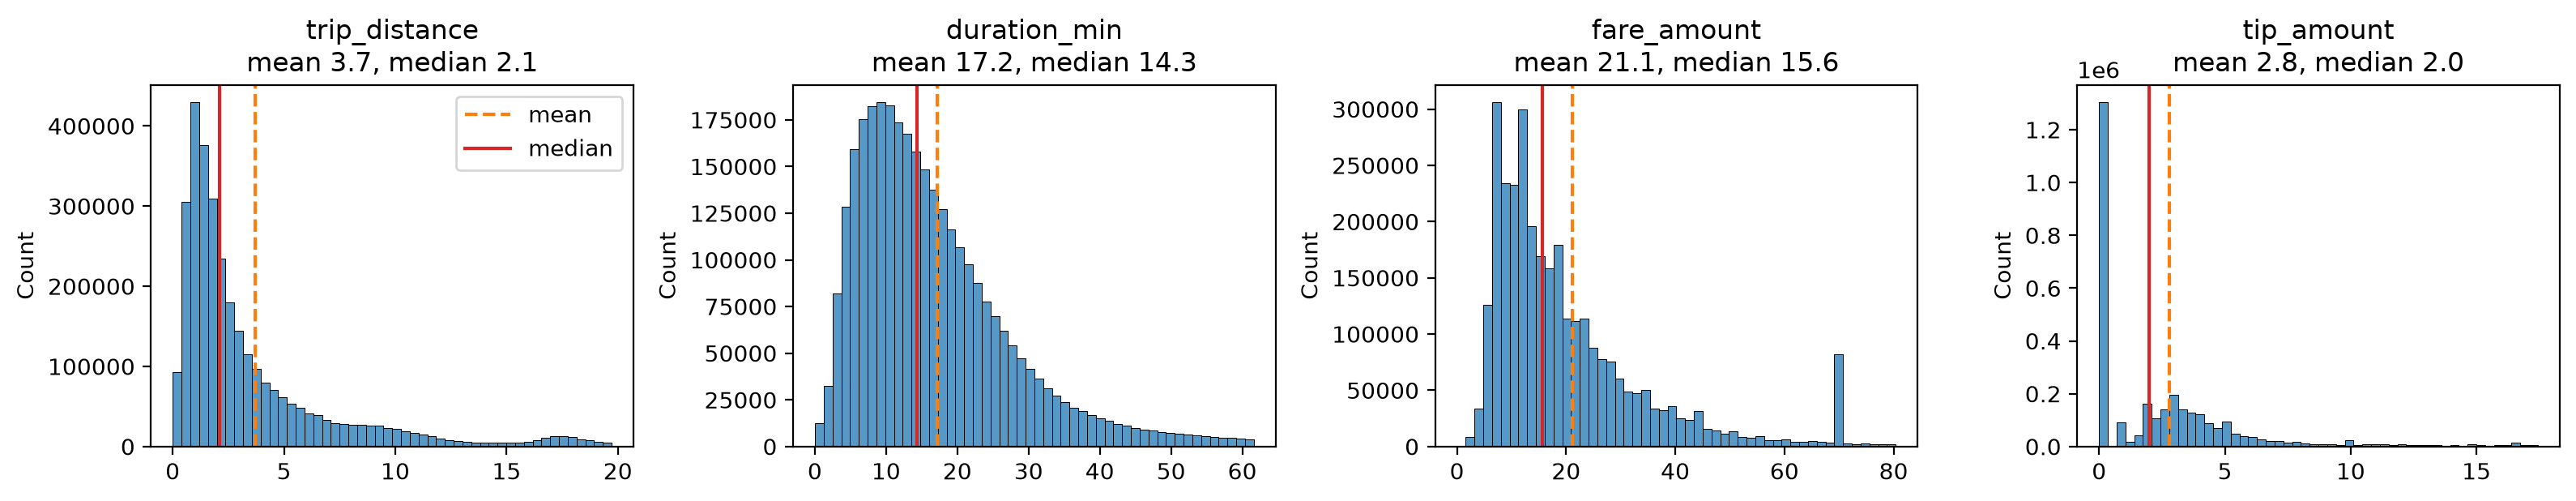

In [82]:
# Shape of the 4 main numbers (top 1% hidden so the bars are readable)
cols = ["trip_distance", "duration_min", "fare_amount", "tip_amount"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))

for ax, col in zip(axes, cols):
    s = clean[col]
    s = s[s <= s.quantile(0.99)]
    sns.histplot(s, bins=50, ax=ax)
    ax.axvline(clean[col].mean(), color="C1", ls="--", label="mean")
    ax.axvline(clean[col].median(), color="C3", label="median")
    ax.set(title=f"{col}\nmean {clean[col].mean():.1f}, median {clean[col].median():.1f}",
           xlabel="")

axes[0].legend()
fig.tight_layout()
plt.show()

**Finding:** a typical trip is about 2 miles, 14 minutes and \$15.6. All four numbers are
right-skewed (mean above median), so **medians** are used from here on. The spike at about \$70 is the
fixed JFK airport fare. About 13 lakh trips show a \$0 tip — explained in 4.3.

### 4.2 Outliers

In [83]:
# IQR rule: count values outside 1.5 × IQR in each column
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    return ((s < q1 - fence) | (s > q3 + fence)).sum()

out = clean[cols].apply(iqr_outliers)
pd.DataFrame({"outliers": out, "percent": (out / len(clean) * 100).round(1)})

,outliers,percent
trip_distance,300812,9.5
duration_min,141037,4.5
fare_amount,206858,6.5
tip_amount,185796,5.9


In [84]:
# The 10 most expensive trips: real or errors?
clean.nlargest(10, "fare_amount")[["trip_distance", "duration_min", "fare_amount",
                                   "RatecodeID", "PULocationID", "DOLocationID"]]

,trip_distance,duration_min,fare_amount,RatecodeID,PULocationID,DOLocationID
2332783,15.26,21.133333,950.0,5.0,195,23
114864,0.01,0.100000,800.0,5.0,163,163
655689,0.32,2.133333,800.0,5.0,101,101
1105867,0.01,0.166667,725.0,5.0,265,265
159224,13.40,53.633333,700.0,5.0,132,265
1265931,97.76,140.750000,670.8,4.0,132,265
1664132,97.26,122.416667,661.7,4.0,132,265
238061,91.13,103.816667,630.9,4.0,230,265
524647,90.62,117.016667,621.1,4.0,132,265
490108,91.35,120.500000,614.8,4.0,138,265


**Finding:** the IQR rule flags 4.5–9.5% of trips — mostly real airport and long out-of-city trips,
so they are **kept**. But some of the top fares are impossible: \$800 for 0.01 miles in 6 seconds.
Each value alone looks possible; together they are not.

In [85]:
# Over $100 for under 1 mile: each value alone looks possible, together they are not
weird = (clean["fare_amount"] > 100) & (clean["trip_distance"] < 1)
print("weird trips:", weird.sum())

clean = clean[~weird]
print("trips left: ", len(clean))

weird trips: 531
trips left:  3161795


**Result:** 531 more trips removed. Final clean data: **31,61,795 trips** (1,74,921 removed in
total, 5.24%).

### 4.3 Relationships

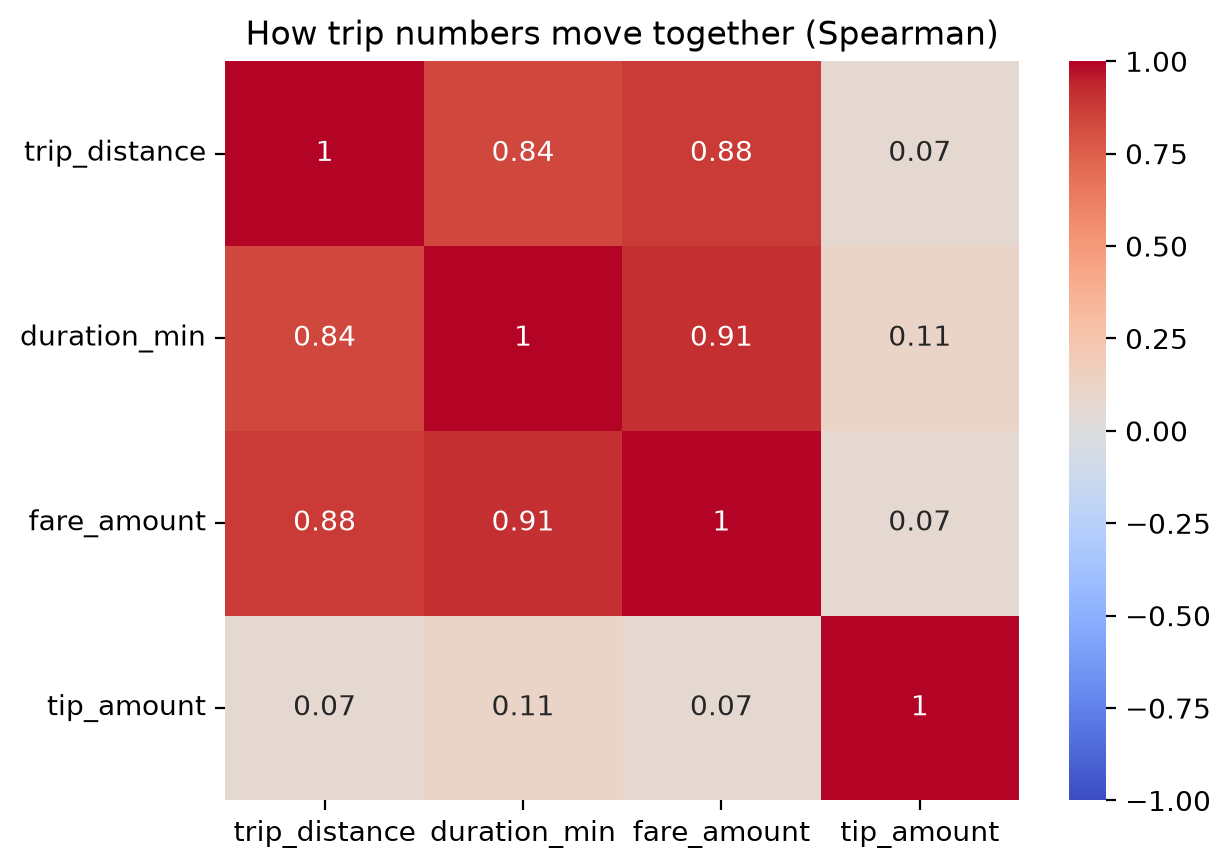

In [86]:
# Spearman correlation: rank-based, so a few huge trips can't distort it
corr = clean[cols].corr(method="spearman").round(2)
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("How trip numbers move together (Spearman)")
plt.show()

**Finding:** distance, time and fare move together strongly (0.84–0.91). Tip is almost unrelated to
all of them (0.07–0.11), which is suspicious. The next two cells explain why.

In [87]:
# Share of trips showing a $0 tip, by payment type
(clean["tip_amount"] == 0).groupby(clean["payment_type"]).mean().round(2)

payment_type
0    0.94
1    0.09
2    1.00
3    1.00
4    1.00
Name: tip_amount, dtype: float64

In [88]:
# Tip correlation for card trips only (the only type where tips are recorded)
card = clean[clean["payment_type"] == 1]
card[cols].corr(method="spearman").round(2)["tip_amount"]

trip_distance    0.54
duration_min     0.57
fare_amount      0.59
tip_amount       1.00
Name: tip_amount, dtype: float64

**Finding:** tips are only reliable for card trips (payment_type 1). Cash tips are not recorded at all
(data dictionary), and app, no-charge and dispute trips almost always show \$0 too. For card trips, 91% of riders tip, and the tip
rises with the fare (Spearman 0.59, up from 0.07). **All tip analysis uses card trips only.**

## 5. Business questions

Each question has one chart, then the answer and a recommendation.

### Q1 — When are taxis busiest?

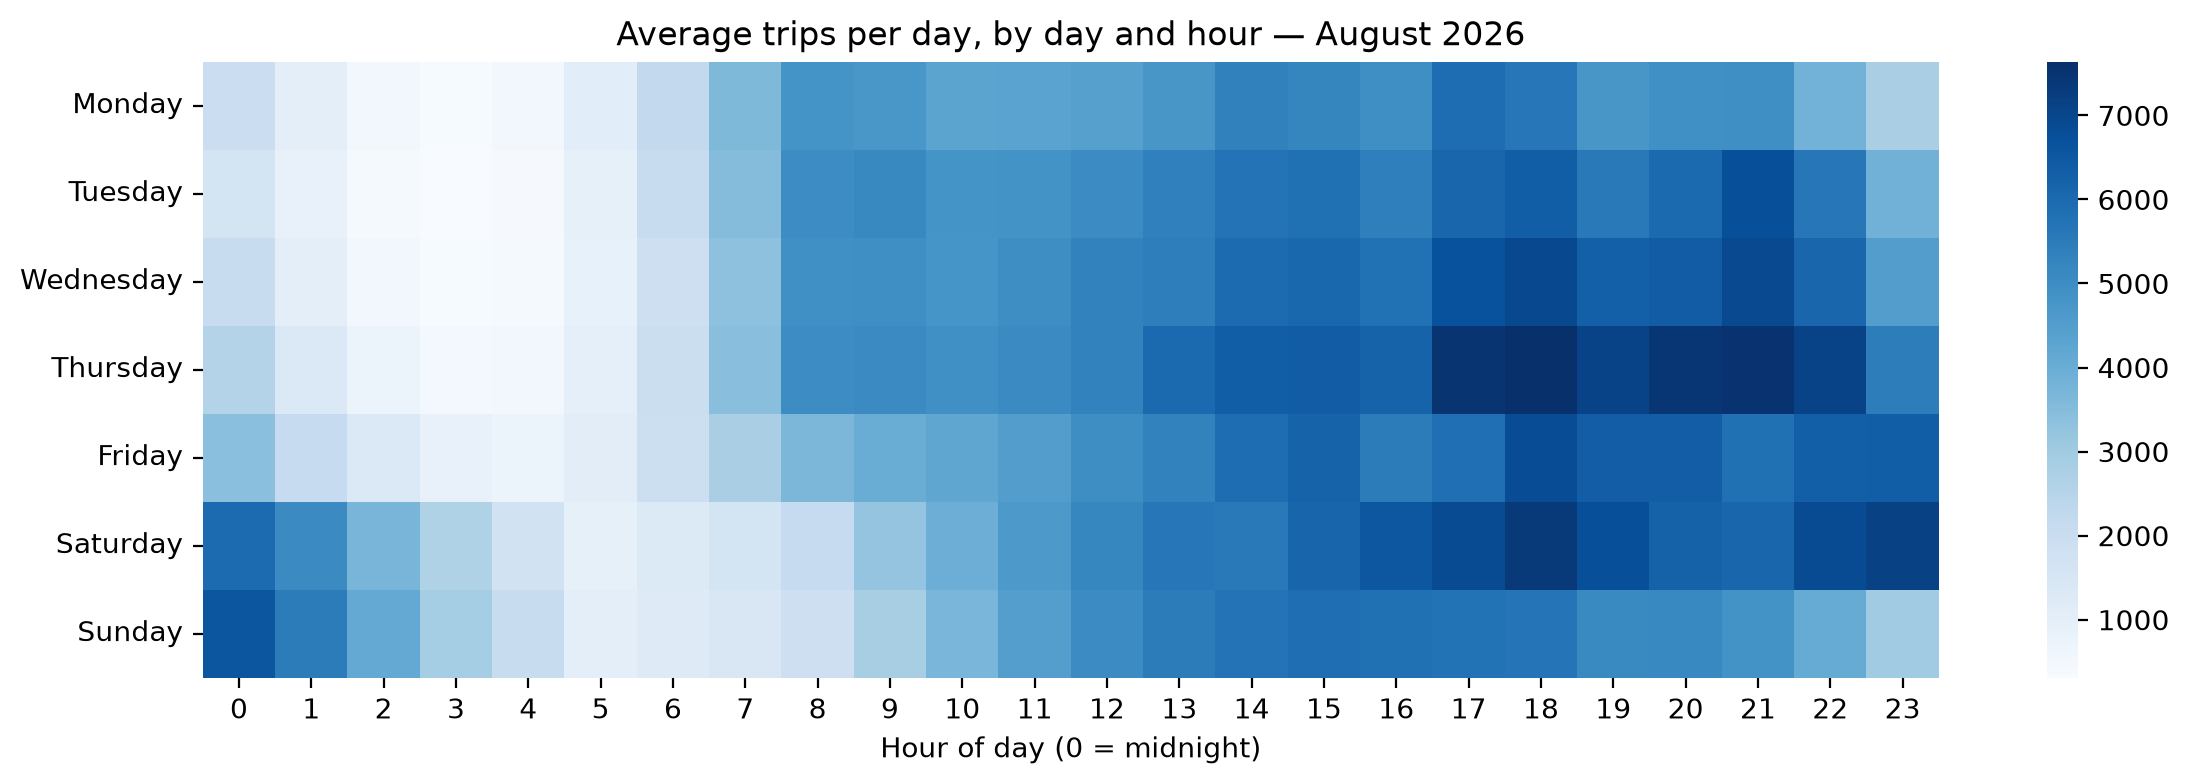

In [89]:
pick = clean["tpep_pickup_datetime"]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Trips for every (day, hour) pair: 7 rows × 24 columns
table = pd.crosstab(pick.dt.day_name(), pick.dt.hour)

# August 2026 has 5 Saturdays, Sundays and Mondays but only 4 of every other day,
# so divide by the number of each weekday -> average trips per day
days_in_month = pd.Series(pd.date_range("2026-08-01", "2026-08-31").day_name()).value_counts()
avg = table.div(days_in_month, axis=0).reindex(day_order)

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(avg, cmap="Blues", ax=ax)
ax.set(title="Average trips per day, by day and hour — August 2026",
       xlabel="Hour of day (0 = midnight)", ylabel="")
plt.show()

In [90]:
# The 5 busiest (day, hour) slots, as average trips in that hour
avg.stack().nlargest(5).round()

tpep_pickup_datetime  tpep_pickup_datetime
Thursday              18                      7636.0
                      21                      7526.0
                      17                      7509.0
                      20                      7481.0
Saturday              18                      7332.0
dtype: float64

**Q1 answer — When are taxis busiest?**

- **Peak:** weekday evenings, 5–9 pm. Four of the five busiest hours are Thursday evening; the
  busiest is Thursday 6–7 pm, with about 7,600 trips on an average Thursday.
- **Weekends:** busy late at night (0–2 am on Saturday and Sunday) and on Saturday evening.
- **Quiet:** 2–6 am on weekdays, and Sunday/Monday evenings.

**Recommendation:** put the most drivers on the road Tuesday–Saturday, 5–10 pm, keep some on Friday
and Saturday nights until 2 am, and run a small crew 2–6 am.

### Q2 — Where do most trips start?

In [91]:
# Share of pickups per borough
borough = clean["PULocationID"].map(zones.set_index("LocationID")["Borough"])
(borough.value_counts(normalize=True, dropna=False) * 100).round(1)

PULocationID
Manhattan        86.9
Queens            9.5
Brooklyn          3.0
Bronx             0.4
Unknown           0.1
NaN               0.0
Staten Island     0.0
EWR               0.0
Name: proportion, dtype: float64

                           Zone    Borough   trips  percent
0                   JFK Airport     Queens  146596      4.6
1                Midtown Center  Manhattan  130649      4.1
2         Upper East Side South  Manhattan  122516      3.9
3  Penn Station/Madison Sq West  Manhattan  111856      3.5
4         Upper East Side North  Manhattan   99994      3.2
5                  Midtown East  Manhattan   95874      3.0
6     Times Sq/Theatre District  Manhattan   92636      2.9
7                  East Village  Manhattan   90889      2.9
8                  East Chelsea  Manhattan   87083      2.8
9                   Murray Hill  Manhattan   85481      2.7


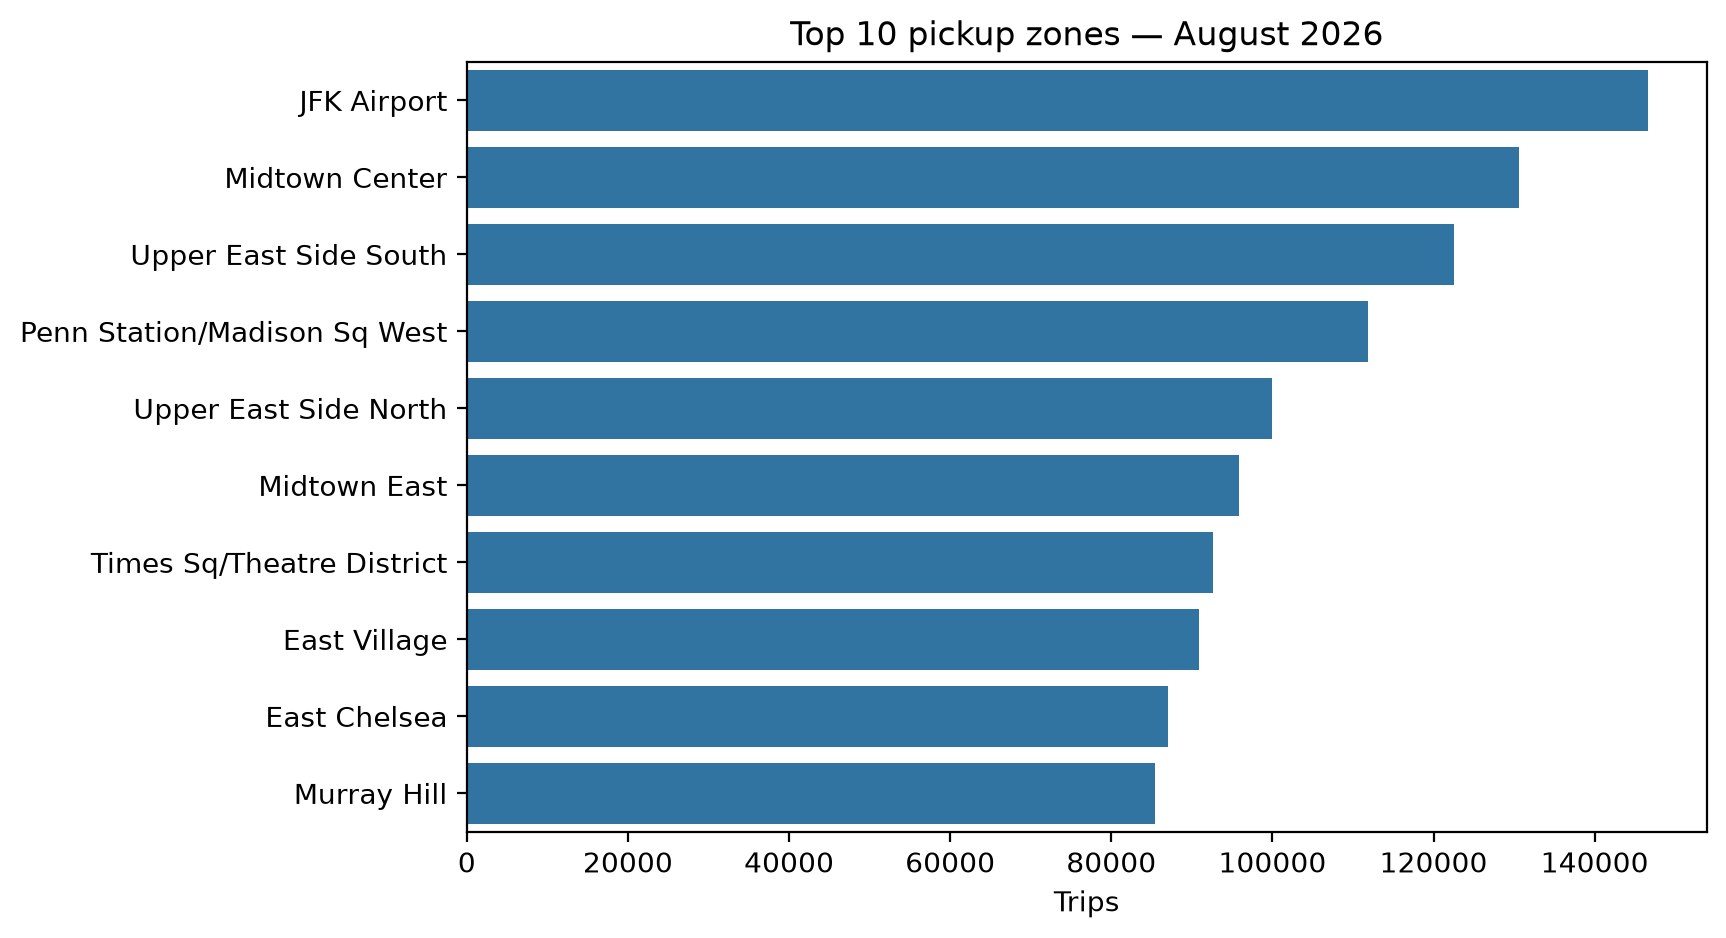

In [92]:
# Top 10 pickup zones (Unknown / Outside NYC removed), with names
top = (clean["PULocationID"]
       .value_counts()
       .drop([264, 265], errors="ignore")
       .head(10)
       .rename_axis("LocationID")
       .reset_index(name="trips"))

top = top.merge(zones, on="LocationID", how="left")
top["percent"] = (top["trips"] / len(clean) * 100).round(1)
print(top[["Zone", "Borough", "trips", "percent"]])

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top, y="Zone", x="trips", color="C0", ax=ax)
ax.set(title="Top 10 pickup zones — August 2026", xlabel="Trips", ylabel="")
plt.show()

**Q2 answer — Where do most trips start?**

- Manhattan gives **86.9%** of all pickups. Queens gives 9.5%, about half of it from JFK Airport.
  Brooklyn 3.0%; the Bronx and Staten Island are almost zero.
- **JFK Airport** is the busiest single pickup zone: 1,46,596 trips (4.6% of all trips).
- The other 9 of the top 10 zones are all in Manhattan: offices (Midtown), Penn Station, the Upper
  East Side, Times Square and the East Village.
- The top 10 zones together give **33.6%** of all trips, out of about 260 zones.

**Recommendation:** keep drivers in Manhattan, especially Midtown, Penn Station and the Upper East
Side, and keep a steady line of taxis at JFK. Outside Manhattan and the airports, there is very
little yellow-taxi business.

### Q3 — Which trips earn the most per minute?

                trips  median_fare  median_min  fare_per_min
length                                                      
under 1 mile   634229         7.20        5.93          1.25
1-3 miles     1376811        13.50       12.35          1.07
3-10 miles     884765        26.41       22.13          1.18
10+ miles      256349        63.20       40.03          1.43


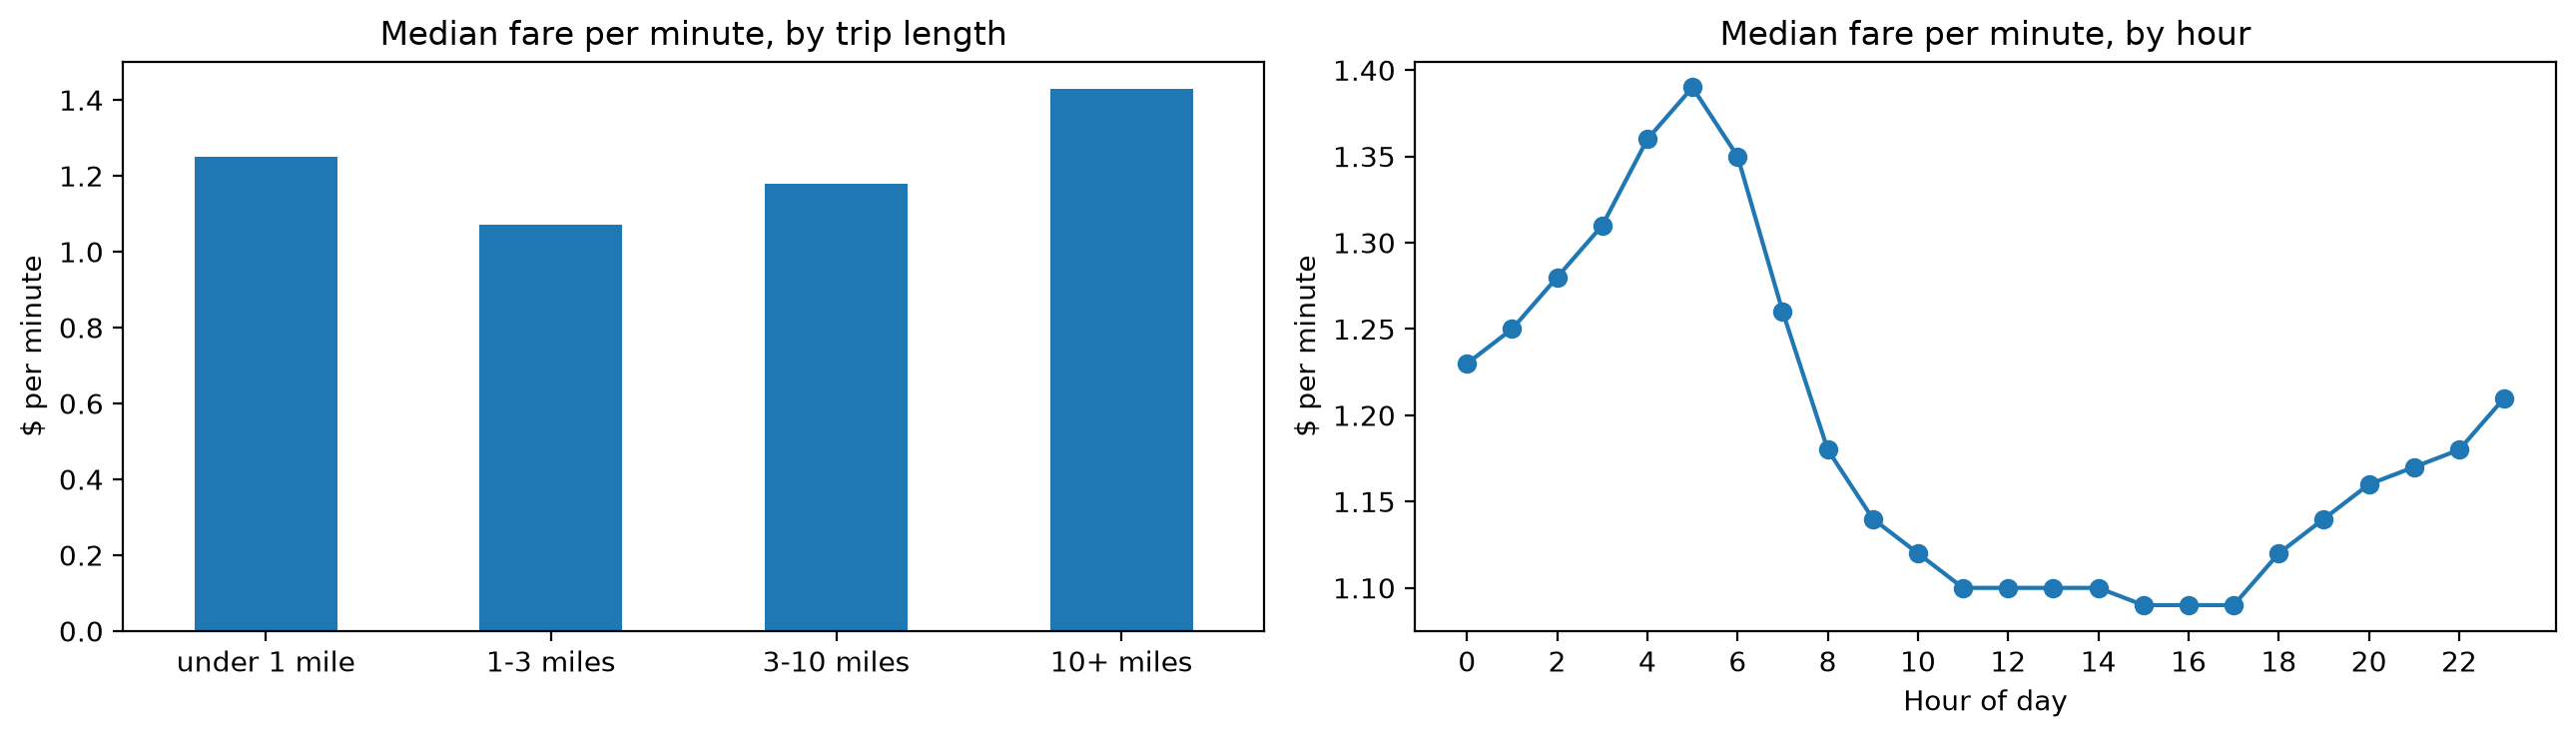

In [93]:
# Fare per minute (trips under 1 minute skipped: tiny times give silly rates)
q3 = clean[clean["duration_min"] >= 1].copy()
q3["fare_per_min"] = q3["fare_amount"] / q3["duration_min"]

# Trip length groups
q3["length"] = pd.cut(q3["trip_distance"],
                      bins=[0, 1, 3, 10, 100],
                      labels=["under 1 mile", "1-3 miles", "3-10 miles", "10+ miles"])

summary = q3.groupby("length", observed=True).agg(
    trips=("fare_per_min", "size"),
    median_fare=("fare_amount", "median"),
    median_min=("duration_min", "median"),
    fare_per_min=("fare_per_min", "median"),
).round(2)
print(summary)

by_hour = q3.groupby(q3["tpep_pickup_datetime"].dt.hour)["fare_per_min"].median().round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
summary["fare_per_min"].plot.bar(ax=axes[0], color="C0", rot=0)
axes[0].set(title="Median fare per minute, by trip length", xlabel="", ylabel="$ per minute")
by_hour.plot(ax=axes[1], marker="o")
axes[1].set(title="Median fare per minute, by hour", xlabel="Hour of day", ylabel="$ per minute")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()

**Q3 answer — Which trips earn the most per minute?**

- By trip length it is a **U-shape**: 10+ mile trips earn the most (\$1.43 per minute), and very short
  trips under 1 mile earn well (\$1.25) because of the fixed starting charge.
- The worst are **1–3 mile trips (\$1.07 per minute)**, slowed by Manhattan traffic — and they are
  also the most common trip (13.8 lakh trips).
- By hour, **early morning pays best** (\$1.39 per minute at 5 am, empty roads) and **midday pays
  worst** (\$1.09–1.10, 11 am–5 pm, traffic).
- The best-paying hours are not the busiest. Q1 showed the evening peak is 5–9 pm, which pays less per
  minute but has many more passengers.

**Recommendation:** long trips and early-morning shifts pay the most per minute, but the data does
not show the empty time between trips. Drivers should weigh the higher rate against the time spent
driving back empty or waiting for the next passenger. The busy evening hours remain the safest money.

*Limit: this measures earnings only while a passenger is in the car.*

### Q4 — How important are airport trips?

             trips        money  % of trips  % of money  avg fare
trip_type                                                        
Airport     290725  16012567.60         9.2        24.0     55.08
City       2871070  50684888.17        90.8        76.0     17.65


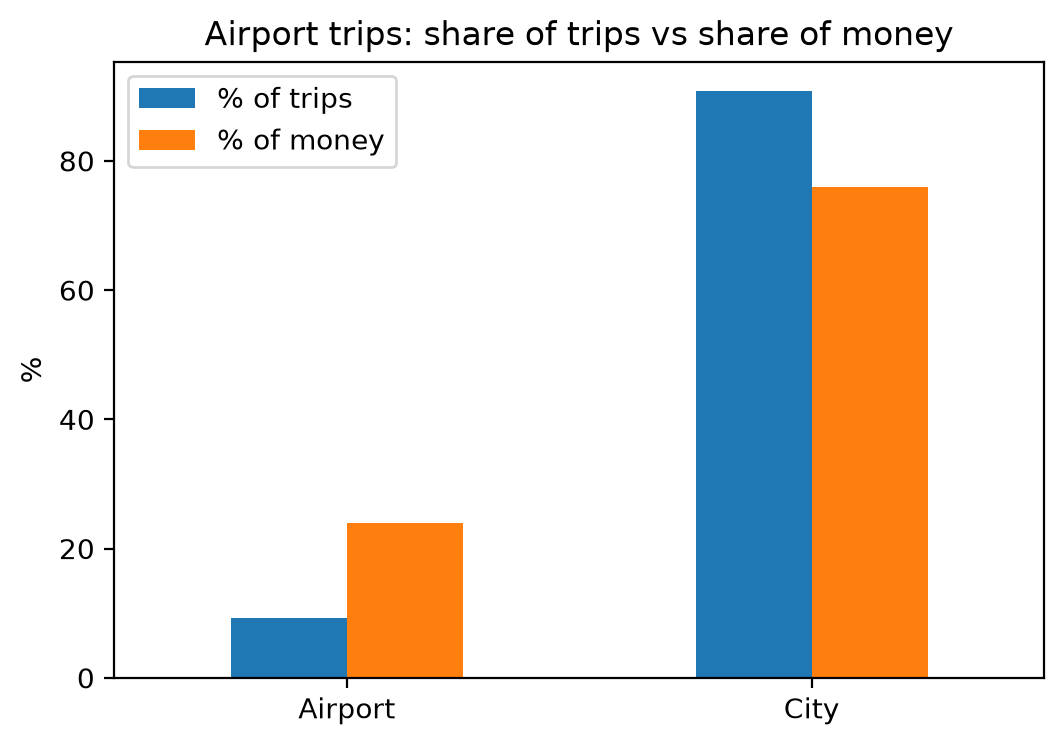

In [94]:
airports = {132: "JFK", 138: "LaGuardia", 1: "Newark"}

# Airport trip = starts OR ends at an airport
is_airport = (clean["PULocationID"].isin(list(airports))
              | clean["DOLocationID"].isin(list(airports)))
clean["trip_type"] = is_airport.map({True: "Airport", False: "City"})

q4 = clean.groupby("trip_type").agg(
    trips=("fare_amount", "size"),
    money=("fare_amount", "sum"),
)
q4["% of trips"] = (q4["trips"] / q4["trips"].sum() * 100).round(1)
q4["% of money"] = (q4["money"] / q4["money"].sum() * 100).round(1)
q4["avg fare"]   = (q4["money"] / q4["trips"]).round(2)
print(q4.round(2))

q4[["% of trips", "% of money"]].plot.bar(rot=0, figsize=(6, 4))
plt.title("Airport trips: share of trips vs share of money")
plt.ylabel("%")
plt.xlabel("")
plt.show()

In [95]:
# Trips from and to each airport
pd.DataFrame({
    "from airport": clean["PULocationID"].map(airports).value_counts(),
    "to airport":   clean["DOLocationID"].map(airports).value_counts(),
})

,from airport,to airport
JFK,146596,28563
LaGuardia,85177,33150
Newark,45,5387


**Q4 answer — How important are airport trips?**

- Airport trips (JFK, LaGuardia, Newark) are only **9.2% of trips but bring 24.0% of all fare money**
  (\$16.0 million of \$66.7 million).
- An average airport trip earns **\$55.08** against **\$17.65** for a city trip, so one airport trip
  is worth about 3 city trips.
- Far more trips leave the airports than go to them: JFK 1,46,596 pickups vs 28,563 drop-offs,
  LaGuardia 85,177 vs 33,150. Travellers going to the airport probably use other options such as Uber
  or Lyft.
- **Newark is one-way:** 5,387 drop-offs but only 45 pickups, because it is in New Jersey.

**Recommendation:** airport pickups at JFK and LaGuardia are the most valuable work in the data. Keep
a steady supply of taxis there. Drivers taking a passenger to JFK or LaGuardia can expect a paid ride
back, while a trip to Newark should be planned as a return journey with no passenger.

### Q5 — Who tips more? (card trips only)

In [96]:
# Card trips only: the only payment type where tips are recorded
card = clean[clean["payment_type"] == 1].copy()
card["tip_pct"] = card["tip_amount"] / card["fare_amount"] * 100
card["tipped"] = (card["tip_amount"] > 0) * 100      # its mean = % of riders who tipped
card["length"] = pd.cut(card["trip_distance"], bins=[0, 1, 3, 10, 100],
                        labels=["under 1 mile", "1-3 miles", "3-10 miles", "10+ miles"])

def tip_summary(by):
    return card.groupby(by, observed=True).agg(
        trips=("tip_pct", "size"),
        tipped_pct=("tipped", "mean"),
        median_tip=("tip_amount", "median"),
        median_tip_pct=("tip_pct", "median"),
    ).round(1)

print(tip_summary("length"), "\n")
print(tip_summary("trip_type"))

               trips  tipped_pct  median_tip  median_tip_pct
length                                                      
under 1 mile  484673        92.5         2.4            32.4
1-3 miles     953949        91.7         3.3            27.0
3-10 miles    397934        86.4         5.6            23.6
10+ miles     157959        91.2        13.6            22.4 

             trips  tipped_pct  median_tip  median_tip_pct
trip_type                                                 
Airport     214836        92.8        11.9            23.3
City       1779679        90.6         3.1            27.0


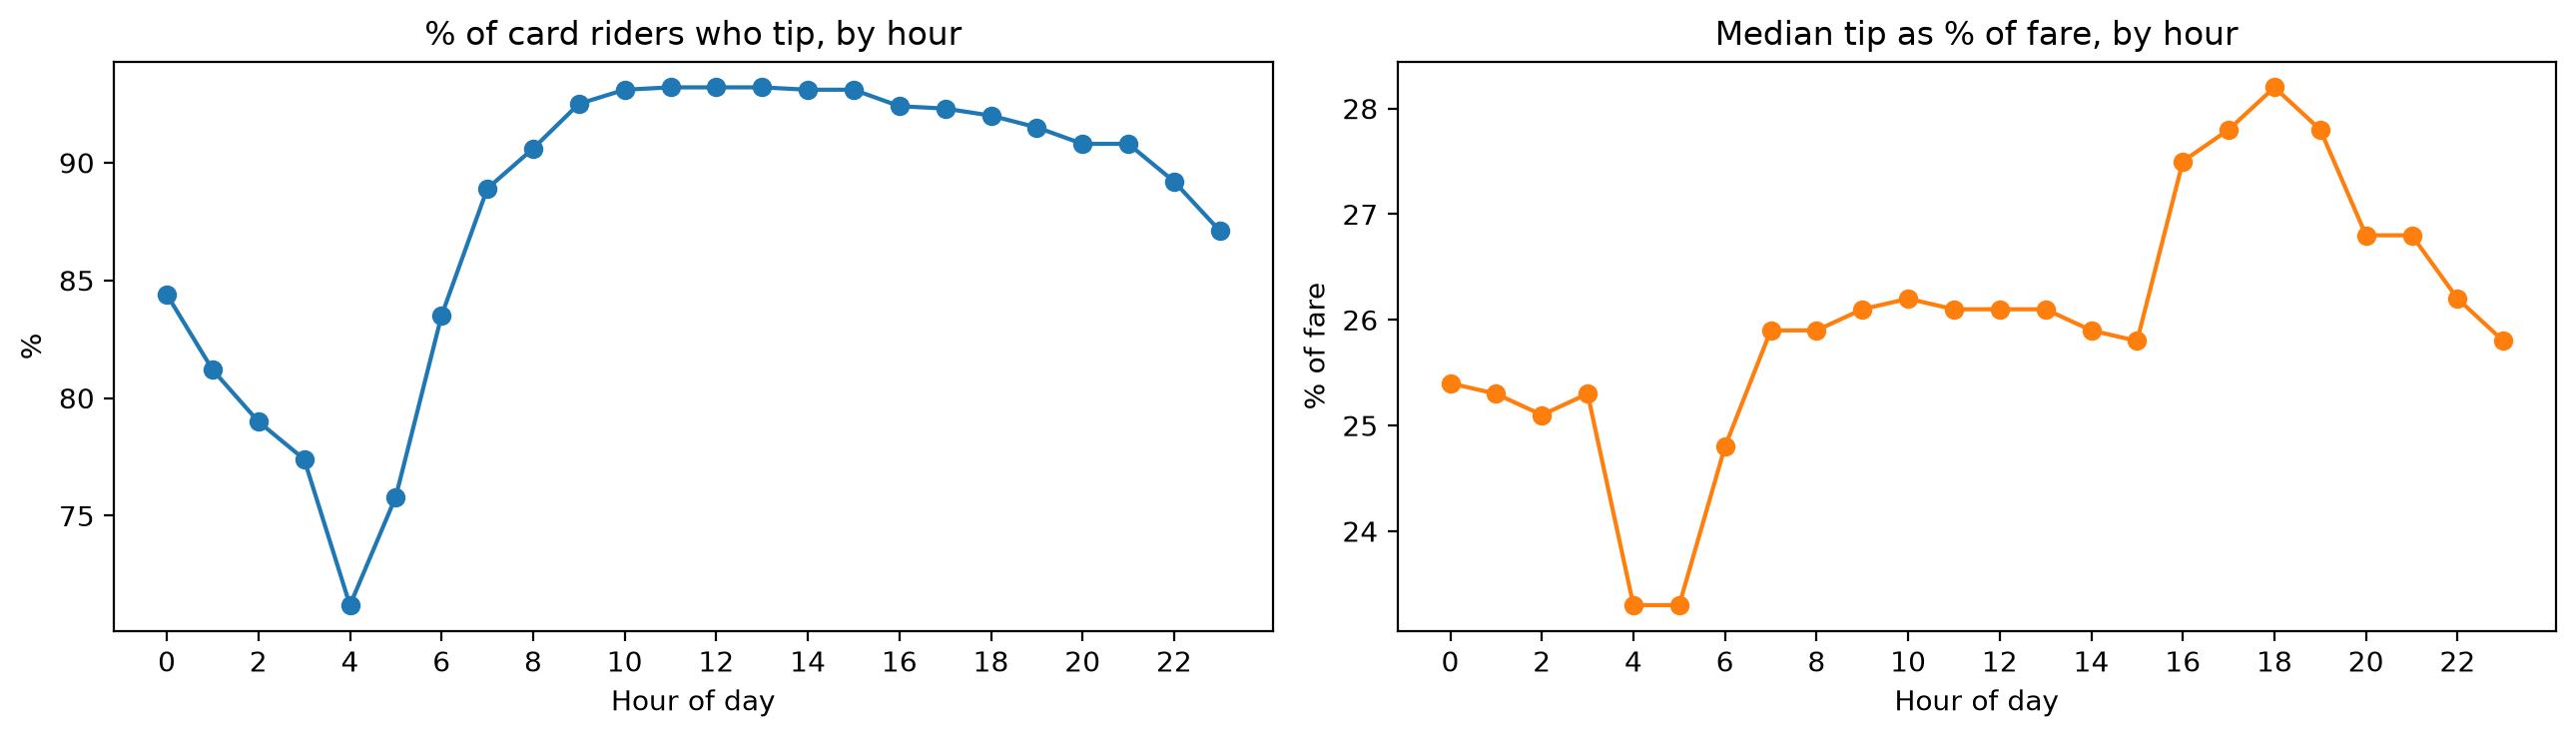

In [97]:
by_hour = tip_summary(card["tpep_pickup_datetime"].dt.hour)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_hour["tipped_pct"].plot(ax=axes[0], marker="o")
axes[0].set(title="% of card riders who tip, by hour", xlabel="Hour of day", ylabel="%")
by_hour["median_tip_pct"].plot(ax=axes[1], marker="o", color="C1")
axes[1].set(title="Median tip as % of fare, by hour", xlabel="Hour of day", ylabel="% of fare")
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()

**Q5 answer — Who tips more?** (card trips only; cash tips are not recorded)

- About **91% of card riders tip**. The share is highest from 9 am to 3 pm (about 93%) and lowest at
  4 am (71%).
- The tip as a % of the fare is **highest in the evening rush, 4–7 pm** (up to 28.2% at 6 pm), and
  lowest at 4–5 am (23.3%).
- The tip in dollars grows with trip length (\$2.4 under 1 mile, \$13.6 for 10+ miles), but the tip %
  falls (32.4% down to 22.4%). Short-trip riders probably round up or tip a minimum amount.
- Airport riders tip more in dollars (\$11.9 vs \$3.1 for city trips), but a smaller % (23.3% vs 27.0%).

**Link to Q3:** the evening rush pays less per minute on the meter, but it gets the highest tips,
which makes up part of the difference.

**Recommendation:** encourage card payment, because only card tips can be seen and measured, and card
riders tip 91% of the time. Evening rush hours are worth more than the meter rate alone suggests.

*Limit: tip % is measured against the fare only; the tip screen may calculate % on the total
including surcharges.*

### Q6 — How big are app bookings?

In [98]:
# payment_type 0 (Flex Fare) = booked in an app; everything else = street hail
clean["booking"] = (clean["payment_type"] == 0).map({True: "App", False: "Street"})
print((clean["booking"].value_counts(normalize=True) * 100).round(1), "\n")

# Which app booked the trip (HV0003 = Uber, HV0005 = Lyft)
apps = clean.loc[clean["booking"] == "App", "request_source"].replace(
    {"HV0003": "Uber", "HV0005": "Lyft"})
(apps.value_counts(normalize=True, dropna=False) * 100).round(1)

booking
Street    73.5
App       26.5
Name: proportion, dtype: float64 



request_source
Uber      68.7
Lyft      19.4
A         11.1
EH0004     0.7
CC         0.1
NaN        0.0
Name: proportion, dtype: float64

           trips  median_distance  median_fare  airport_pct
booking                                                    
App       838278              3.5         22.6          1.6
Street   2323517              1.7         13.5         11.9


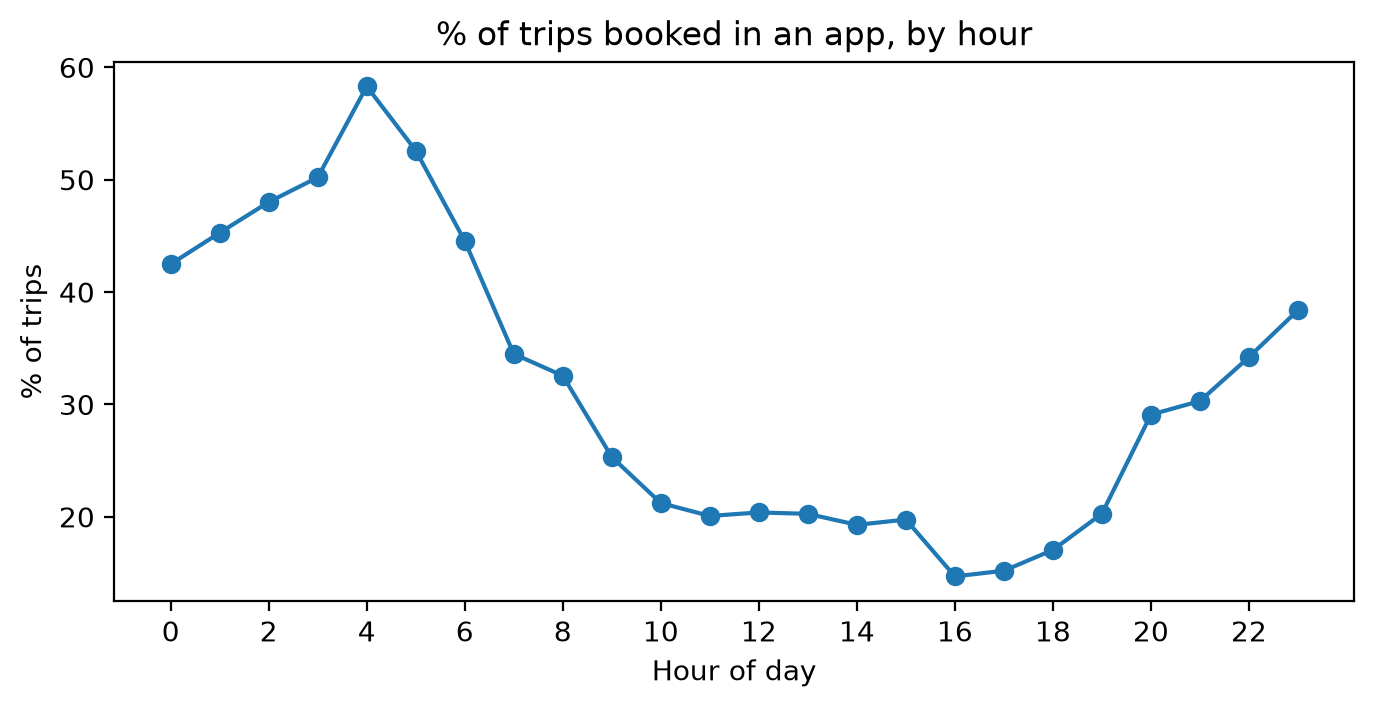

In [99]:
# App vs street trips
print(clean.groupby("booking").agg(
    trips=("fare_amount", "size"),
    median_distance=("trip_distance", "median"),
    median_fare=("fare_amount", "median"),
    airport_pct=("trip_type", lambda s: (s == "Airport").mean() * 100),
).round(1))

# % of trips booked in an app, by hour
app_share = (clean["booking"] == "App").groupby(clean["tpep_pickup_datetime"].dt.hour).mean() * 100

app_share.plot(marker="o", figsize=(8, 3.5))
plt.title("% of trips booked in an app, by hour")
plt.xlabel("Hour of day")
plt.ylabel("% of trips")
plt.xticks(range(0, 24, 2))
plt.show()

**Q6 answer — How big are app bookings?**

- **26.5% of all trips** are booked through an app (Flex Fare).
- **Uber books 68.7%** of app trips, Lyft 19.4%, and others 11.9%. Uber alone books about 18% of all
  yellow taxi trips.
- App trips are longer and pay more than street trips: median 3.5 miles vs 1.7 miles, and a fare of
  \$22.6 vs \$13.5.
- App trips rarely involve airports (1.6% vs 11.9% of street trips).
- **Apps dominate at night:** 58% of trips at 4 am are app bookings, against only about 15% at 4–5 pm.

**Recommendation:** drivers working nights and early mornings should be on Uber, because most of
their trips come from apps at those hours. In the busy afternoon and evening, street hail is enough.

In [100]:
# Export the clean data for Power BI (only the columns the dashboard needs)
bi = clean.assign(
    pickup_date=clean["tpep_pickup_datetime"].dt.date,   # date and hour instead of the full
    pickup_hour=clean["tpep_pickup_datetime"].dt.hour,   # timestamp keeps the .pbix file small
)[["pickup_date", "pickup_hour", "PULocationID", "DOLocationID", "trip_distance",
   "duration_min", "fare_amount", "tip_amount", "payment_type", "trip_type", "booking",
   "request_source"]]

bi.to_parquet("taxi_clean_powerbi.parquet", index=False)
print(bi.shape)     

(3161795, 12)


## 6. Summary

**Data:** 33,36,716 trips. 1,74,921 bad trips removed (5.24%), leaving 31,61,795 clean trips.

**Key findings**

1. **When:** busiest on weekday evenings, 5–9 pm, with Thursday the peak. Weekends are busy at
   0–2 am and on Saturday evening. 2–6 am is quiet.
2. **Where:** Manhattan gives 86.9% of pickups. JFK is the single busiest zone (4.6%), and 10 zones
   give a third of all trips.
3. **Earnings:** 10+ mile trips earn the most per minute (\$1.43), and 1–3 mile trips, the most
   common, earn the least (\$1.07). Early morning pays best per minute, midday worst.
4. **Airports:** 9.2% of trips but 24.0% of fare money. An airport trip is worth about 3 city trips.
   Newark trips come back empty.
5. **Tips:** 91% of card riders tip. Tip % is highest in the evening rush (28.2% at 6 pm) and lowest
   at 4 am.
6. **Apps:** 26.5% of trips are app bookings, mostly Uber. They are longer, pay more, and make up 58%
   of trips at 4 am.

**Recommendations**

1. Put the most drivers on the road Tuesday–Saturday, 5–10 pm, in Midtown, Penn Station and the Upper
   East Side.
2. Keep a steady supply of taxis at JFK and LaGuardia, the most valuable trips in the data.
3. Night and early-morning drivers should be on Uber, where most of their trips come from.
4. Encourage card payment, because only card tips can be measured.

**Limits**

- One month only (August). Other months may look different.
- The data does not show the time drivers spend empty between trips.
- Tips are recorded only for card payments.
- The meaning of request_source codes A, CC and EH is unknown.